# 09 — Posisi layout dan detail header
Acuan eksperimen adalah ensemble ConvNeXt dengan skor leaderboard 0,88289 yang dilaporkan pengguna. Pada holdout, model itu mengklasifikasikan 88,3815% dari 6.395 halaman dengan benar. Hipotesisnya adalah informasi tentang posisi teks dan detail judul halaman dapat membantu mengenali jenis dokumen.

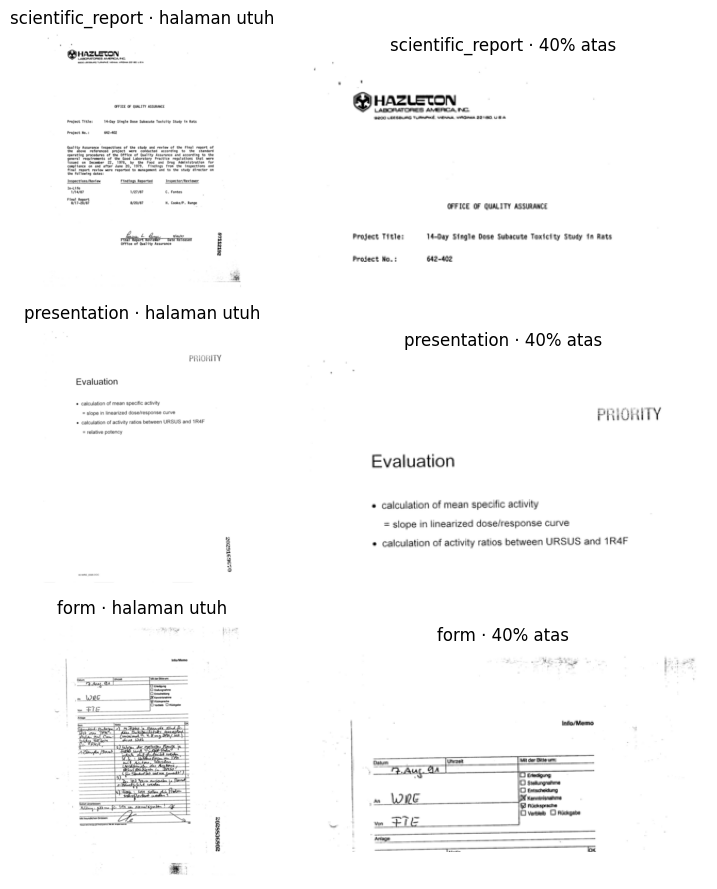

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.preprocess import read_metadata, data_directory
from scripts.spatial_layout import PageViews
from scripts.predict import validate_submission
cfg = json.loads((ROOT / 'configs/spatial_layout.json').read_text())
run = ROOT / 'reports/spatial_layout'
selection_dir = ROOT / 'reports/spatial_selection'
train, test, sample = read_metadata(data_directory())
split = pd.read_csv(run / 'split.csv')
fit = train[train.id.isin(split.loc[split.split.eq('train'), 'id'])]
examples = fit[fit.class_name.isin(['scientific_report', 'presentation', 'form'])].drop_duplicates('class_name')
views = PageViews(examples, data_directory(), cfg)
fig, axes = plt.subplots(len(examples), 2, figsize=(8, 9))
for i, name in enumerate(examples.class_name):
    for ax, pixels, title in zip(axes[i], views[i], ('halaman utuh', '40% atas')):
        ax.imshow(pixels, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{name} · {title}')
        ax.axis('off')
fig.tight_layout()
plt.show()

## Training dan evaluasi
Checkpoint ConvNeXt berasal dari split training yang sama. Dari dua tampilan setiap halaman, fitur tahap ketiga dan keempat diringkas per wilayah. Grid halaman utuh berukuran 3×3 dan 2×2. Grid header berukuran 2×3 dan 1×1. Classifier PyTorch menerima gabungan fitur tersebut dan dilatih selama 16 epoch. Epoch dengan accuracy holdout tertinggi dipakai untuk inferensi.

In [2]:
display(json.loads((run / 'run.json').read_text()))
display(pd.read_csv(run / 'history.csv'))
selection = json.loads((selection_dir / 'selection.json').read_text())
display(pd.read_csv(selection_dir / 'candidates.csv'))
display(pd.read_csv(selection_dir / 'class_comparison.csv').sort_values('delta_f1'))
display(Markdown((selection_dir / 'interpretation.md').read_text(encoding='utf-8')))

{'config': {'run_name': 'spatial_layout',
  'model': 'spatial_head',
  'source': 'convnext_diversity',
  'page_wh': [320, 416],
  'header_wh': [384, 192],
  'header_fraction': 0.4,
  'hidden': 384,
  'epochs': 16,
  'batch_size': 256,
  'extract_batch_size': 24,
  'workers': 2,
  'learning_rate': 0.0007,
  'weight_decay': 0.02,
  'label_smoothing': 0.05,
  'seed': 42},
 'metadata_digest': '7d3d83196e1e9ae8aad8d980fbe579e496da5999e2e36f2622f0eeb4d08b179e',
 'source_checkpoint_sha256': '9d29b5b128d7b6e5b7948f5d196157dc1145fb87fef177a26d9423470a8f52ad',
 'feature_width': 9600,
 'device': 'cuda',
 'train_rows': 25607,
 'validation_rows': 6395}

,epoch,train_loss,accuracy,macro_f1,val_loss,seconds
0,1,1.085945,0.779828,0.777306,0.751202,1.456712
1,2,0.836161,0.789679,0.787292,0.715256,0.495894
2,3,0.749070,0.796716,0.793271,0.678429,0.543284
3,4,0.690674,0.807349,0.807449,0.669277,0.417208
4,5,0.643485,0.805629,0.803111,0.661433,0.394320
5,6,0.605604,0.813761,0.811839,0.638940,0.385045
6,7,0.575502,0.817045,0.813519,0.637495,0.379265
7,8,0.546227,0.817357,0.814765,0.630238,0.427822
8,9,0.522626,0.820328,0.818612,0.634022,0.378276
9,10,0.503179,0.822205,0.820519,0.631837,0.394819


,variant,weights,accuracy,macro_f1
0,previous,"[0.16666666666666666, 0.16666666666666666, 0.1...",0.883815,0.883172
1,spatial_only,"[0, 0, 0, 0, 0, 1]",0.829554,0.828078
2,spatial_20,"[0.13333333333333333, 0.13333333333333333, 0.1...",0.884441,0.883732
3,spatial_40,"[0.09999999999999999, 0.09999999999999999, 0.0...",0.883034,0.882224


,class_name,previous_f1,selected_f1,delta_f1
6,invoice,0.878581,0.871935,-0.006647
3,file_folder,0.931792,0.925373,-0.006419
4,form,0.773856,0.768627,-0.005229
7,letter,0.900538,0.898396,-0.002142
2,email,0.974967,0.973684,-0.001283
12,resume,0.926267,0.926999,0.000732
1,budget,0.860825,0.861935,0.001111
15,specification,0.908602,0.910811,0.002209
8,memo,0.927607,0.929889,0.002282
5,handwritten,0.942761,0.945129,0.002368


# Pemilihan spatial_selection

Kandidat terpilih: **spatial_20**, bobot [0.13333333333333333, 0.13333333333333333, 0.13333333333333333, 0.13333333333333333, 0.26666666666666666, 0.2].

| Kandidat | Accuracy validasi | Macro-F1 |
| --- | ---: | ---: |
| previous | 88.3815% | 0.883172 |
| spatial_only | 82.9554% | 0.828078 |
| spatial_20 | 88.4441% | 0.883732 |
| spatial_40 | 88.3034% | 0.882224 |

Perubahan terhadap kandidat pertama: +0.06 poin persentase accuracy pada 6,395 halaman validasi yang sama.
Memperbaiki 40 kesalahan dan menambah 36 kesalahan. F1 meningkat pada 11 dari 16 kelas.

Kelas terlemah: scientific_report (0.759), presentation (0.768), form (0.769).

Manfaat komponen baru dinilai melalui hasil kandidat tunggal dan gabungan. Eksperimen ini tidak memisahkan efek arsitektur, resolusi, inisialisasi, dan jadwal training secara kausal.

Holdout yang sama sudah digunakan untuk memilih checkpoint dan kandidat. Tidak ada evaluasi CV independen setelah tuning. Tidak ada label test atau lookup duplikat test yang dipakai. Skor leaderboard baru harus dicatat setelah submission.

File: `submissions/submission_spatial_selected.csv` (7,994 baris). Hash dan rincian komponen tersedia di `selection.json`.

## Pemilihan submission
Bobot model layout dalam empat kandidat adalah 0%, 100%, 20% dan 40%. Sisa bobot mengikuti proporsi ensemble yang mendapat skor 0,88289. Kandidat dengan akurasi validasi tertinggi dipilih, dengan prioritas pada ensemble sebelumnya jika seri. Penggunaan holdout yang sama untuk pemilihan epoch dan kandidat membatasi interpretasi kenaikan lokal.

## Uji posisi input
Sesudah tahap layout, satu perbandingan tambahan menguji rata-rata lima posisi pada lima CNN. Pergeseran diagonal adalah 3 piksel pada resolusi 224 dan 4 piksel pada 320. Setiap posisi mendapat bobot ⅕. Kedua kandidat memakai bobot ensemble tahap layout yang sama. Seluruh pemilihan berlangsung pada holdout yang juga dipakai dalam eksperimen sebelumnya.

In [3]:
final_dir = ROOT / 'reports/shift_selection'
selection = json.loads((final_dir / 'selection.json').read_text())
display(pd.read_csv(final_dir / 'candidates.csv'))
display(Markdown((final_dir / 'interpretation.md').read_text(encoding='utf-8')))
scored = pd.read_csv(ROOT / 'reports/convnext_selection/validation_predictions.csv').set_index('id').sort_index()
latest = pd.read_csv(final_dir / 'validation_predictions.csv').set_index('id').sort_index()
assert scored.index.equals(latest.index) and scored.label.equals(latest.label)
a = scored.prediction.eq(scored.label)
b = latest.prediction.eq(latest.label)
print('Perbaikan terhadap submission 0,88289:', int((~a & b).sum()), 'kesalahan baru:', int((a & ~b).sum()))
display(pd.read_csv(final_dir / 'class_comparison.csv').sort_values('delta_f1'))

,variant,weights,accuracy,macro_f1
0,spatial_20_center,"[0.13333333333333333, 0.13333333333333333, 0.1...",0.884441,0.883732
1,spatial_20_shift,"[0, 0, 0, 0, 0, 0.2, 0.13333333333333333, 0.13...",0.884754,0.884134


# Pemilihan shift_selection

Kandidat terpilih: **spatial_20_shift**, bobot [0, 0, 0, 0, 0, 0.2, 0.13333333333333333, 0.13333333333333333, 0.13333333333333333, 0.13333333333333333, 0.26666666666666666].

| Kandidat | Accuracy validasi | Macro-F1 |
| --- | ---: | ---: |
| spatial_20_center | 88.4441% | 0.883732 |
| spatial_20_shift | 88.4754% | 0.884134 |

Perubahan terhadap kandidat pertama: +0.03 poin persentase accuracy pada 6,395 halaman validasi yang sama.
Memperbaiki 35 kesalahan dan menambah 33 kesalahan. F1 meningkat pada 8 dari 16 kelas.

Kelas terlemah: scientific_report (0.763), presentation (0.765), form (0.774).

Bobot ensemble sama pada kedua kandidat. Perbedaan skor mengukur dampak rata-rata prediksi lima posisi input.

Holdout yang sama dipakai untuk pemilihan checkpoint dan kandidat. Skor leaderboard menunggu hasil unggah.

File: `submissions/submission_shift_selected.csv` (7,994 baris). Hash dan rincian komponen tersedia di `selection.json`.

Perbaikan terhadap submission 0,88289: 55 kesalahan baru: 49


,class_name,previous_f1,selected_f1,delta_f1
11,questionnaire,0.868766,0.864652,-0.004115
7,letter,0.898396,0.894526,-0.003870
13,scientific_publication,0.928230,0.924731,-0.003498
3,file_folder,0.925373,0.922374,-0.002999
10,presentation,0.767528,0.764706,-0.002822
8,memo,0.929889,0.927250,-0.002639
2,email,0.973684,0.972405,-0.001279
5,handwritten,0.945129,0.944882,-0.000247
6,invoice,0.871935,0.872777,0.000842
15,specification,0.910811,0.911805,0.000994


In [4]:
path = ROOT / selection['submission']
submission = pd.read_csv(path)
validate_submission(submission, sample)
assert len(submission) == len(test) == 7994
assert hashlib.sha256(path.read_bytes()).hexdigest() == selection['submission_sha256']
old = json.loads((ROOT / 'reports/convnext_selection/selection.json').read_text())
assert hashlib.sha256((ROOT / old['submission']).read_bytes()).hexdigest() == old['submission_sha256']
print(selection['selected']['variant'], len(submission), path.name)
display(submission.head())

spatial_20_shift 7994 submission_shift_selected.csv


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
